In [1]:

import pandas as pd
import numpy as np
from Bio.Data import CodonTable
from Bio import SeqIO
from Bio.Seq import Seq
from Bio.SeqUtils import seq3
import random
from Bio.SeqUtils import GC123
import multiprocessing as mp

import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D



fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager

font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['figure.dpi'] = 300
plt.rcParams['svg.fonttype']='none'

In [2]:
from Bio import SeqIO

In [74]:
#Unzip endosymbiont genome
!gunzip "JAHXDM01.1.fsa_nt.gz"

In [29]:
#annotate endosymbiont genome with prokka 
!singularity exec "/cvmfs/singularity.galaxyproject.org/p/r/prokka:1.14.6--pl5321hdfd78af_5" prokka "JAHXDM01.1.fsa_nt"

[19:14:01] This is prokka 1.14.6
[19:14:01] Written by Torsten Seemann <torsten.seemann@gmail.com>
[19:14:01] Homepage is https://github.com/tseemann/prokka
[19:14:01] Local time is Wed Jun 12 19:14:01 2024
[19:14:01] You are rkapoor
[19:14:01] Operating system is linux
[19:14:01] You have BioPerl 1.7.8
Argument "1.7.8" isn't numeric in numeric lt (<) at /usr/local/bin/prokka line 259.
[19:14:01] System has 112 cores.
[19:14:01] Will use maximum of 8 cores.
[19:14:01] Annotating as >>> Bacteria <<<
[19:14:01] Generating locus_tag from 'JAHXDM01.1.fsa_nt' contents.
[19:14:01] Setting --locustag NOLMGPCI from MD5 785609c28c7d26602a35e273748f494f
[19:14:01] Creating new output folder: PROKKA_06122024
[19:14:01] Running: mkdir -p PROKKA_06122024
[19:14:01] Using filename prefix: PROKKA_06122024.XXX
[19:14:01] Setting HMMER_NCPU=1
[19:14:01] Writing log to: PROKKA_06122024/PROKKA_06122024.log
[19:14:01] Command: /usr/local/bin/prokka JAHXDM01.1.fsa_nt
[19:14:01] Appending to PATH: /usr/loca

In [31]:
#make endosymbiont blastp database from predicted protein sequences , after moving prokka to outputs
%%bash
cd "outputs/PROKKA_06122024"
singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond makedb --in "PROKKA_06122024.faa" -d 'prot'

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 112
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Database input file: PROKKA_06122024.faa
Opening the database file...  [0.009s]
Loading sequences...  [0.003s]
Masking sequences...  [0.014s]
Writing sequences...  [0s]
Hashing sequences...  [0.001s]
Loading sequences...  [0s]
Writing trailer...  [0s]
Closing the input file...  [0s]
Closing the database file...  [0.024s]

Database sequences  2134
  Database letters  639056
     Database hash  917823a1b0639b4b6f95dc70d88ee2b5
        Total time  0.054000s


In [3]:
input_file = open(f"outputs/DIAMOND_htgs.fasta")
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [10]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col=0)

In [7]:
##write fasta of hgt proteins
f=open('outputs/hgts.fasta','w')
for x in set(dfriso[dfriso.tree_HTG].accession):
    f.write(f">{x}\n")
    f.write(str(fasta[x].seq)+"\n")
f.close()


In [9]:
input_file = open(f"outputs/hgts.fasta")
fasta = SeqIO.to_dict(SeqIO.parse(input_file, "fasta"))

In [10]:
len(fasta)

1517

In [13]:
%%bash
singularity exec /cvmfs/singularity.galaxyproject.org/d/i/diamond:2.0.15--hb97b32f_1 diamond blastp --db "outputs/PROKKA_06122024/prot.dmnd"  --query "outputs/hgts.fasta" --out "outputs/endosymbiont_dmnd.tsv" --outfmt 6 qseqid sseqid stitle qtitle qcovhsp pident evalue bitscore qstart qend  --threads 90 --evalue .001  -k 10 --sensitive 

diamond v2.0.15.153 (C) Max Planck Society for the Advancement of Science
Documentation, support and updates available at http://www.diamondsearch.org
Please cite: http://dx.doi.org/10.1038/s41592-021-01101-x Nature Methods (2021)

#CPU threads: 90
Scoring parameters: (Matrix=BLOSUM62 Lambda=0.267 K=0.041 Penalties=11/1)
Temporary directory: 
#Target sequences to report alignments for: 10
Opening the database...  [0.015s]
Database: outputs/PROKKA_06122024/prot.dmnd (type: Diamond database, sequences: 2134, letters: 639056)
Block size = 2000000000
Opening the input file...  [0.002s]
Opening the output file...  [0.005s]
Loading query sequences...  [0.001s]
Masking queries...  [0.014s]
Algorithm: Double-indexed
Building query histograms...  [0.011s]
Allocating buffers...  [0.001s]
Loading reference sequences...  [0.001s]
Masking reference...  [0.005s]
Initializing temporary storage...  [0.19s]
Building reference histograms...  [0.012s]
Allocating buffers...  [0.001s]
Processing query bloc

In [3]:
from collections import Counter

In [4]:
symbdf=pd.read_csv("outputs/endosymbiont_dmnd.tsv",sep="\t", names="qseqid sseqid stitle qtitle qcovhsp pident evalue bitscore qstart qend".split(" "))


In [5]:
min_indices = symbdf.groupby('qseqid')['bitscore'].idxmax()

# Select the rows with the highest bitscore for each qseqid
sdf2=symbdf.loc[min_indices]

In [6]:
sdf2=sdf2.set_index('qseqid').sort_values("evalue")

In [11]:
for x, row in sdf2.iterrows():
    
    sdf2.loc[x,['top_NR_sseqid', 'top_NR_bitscore','top_NR_sciname']]=list(dfriso.loc[x,['sseqid', 'bitscore','sciname']])

In [12]:
sdf2.sort_values('bitscore',ascending=False).to_csv('outputs/bradysia_endosymbiont_blast_top_hits.csv')

In [13]:
sdf2=pd.read_csv('outputs/bradysia_endosymbiont_blast_top_hits.csv',index_col=0)

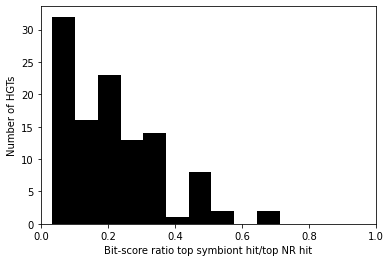

In [27]:
plt.hist(sdf2.bitscore/sdf2.top_NR_bitscore, color='black')
plt.xlabel("Bit-score ratio top symbiont hit/top NR hit")
plt.ylabel("Number of HGTs")
plt.xlim(0,1)
plt.savefig('figures/endosymbiont_top_diamond_by_hgt.svg',format='svg',bbox_inches='tight')

In [15]:
sdf2.shape[0]

111